# 중간고사 템플릿 (셀 1~5)

시험 때 `midterm_form.ipynb`의 셀 1~5에 아래 코드 셀을 하나씩 붙여 넣는다. 셀 순서와 양식의 제목 주석은 바꾸지 않는다.
이 마크다운 칸은 붙여 넣지 않는다 (제출 노트북에는 코드와 출력만).

바꿀 곳은 셀 1 맨 위의 설정 몇 줄이다.

| 문제 유형 | OPTION | TASK | 그 밖의 설정 |
|---|---|---|---|
| 반려동물 영역 (과제1과 같음) | "pet" | "binary" | PET_POSITIVE = [1] |
| 반려동물 + 경계까지 대상 | "pet" | "binary" | PET_POSITIVE = [1, 3] |
| 반려동물 / 배경 / 경계 3클래스 | "pet" | "multi" | 셀 3에서 CLASS_WEIGHT 고려 |
| VOC에서 한 종류(예: 사람)만 | "voc" | "binary" | VOC_TARGET = [15], 셀 3 POS_WEIGHT = "auto" |
| VOC 21클래스 전부 | "voc" | "multi" | |

VOC 클래스 번호: 0 배경, 1 aeroplane, 2 bicycle, 3 bird, 4 boat, 5 bottle, 6 bus, 7 car, 8 cat, 9 chair, 10 cow, 11 diningtable, 12 dog, 13 horse, 14 motorbike, 15 person, 16 pottedplant, 17 sheep, 18 sofa, 19 train, 20 tvmonitor, 255 경계(무시)

device: cuda
원본: 학습 3680장, 시험 3669장


  3680장 전처리 (20초)


  500장 전처리 (3초)
len(train_set) 3680, len(test_set) 500, 에폭당 배치 230


입력 (3, 128, 128) torch.float32 | 정답 (128, 128) torch.int64 | 정답 값 [0, 1]
무시 픽셀(IGNORE) 비율: 0.0%


대상 픽셀 비율: 30.0% | 대상이 없는 사진 비율: 0.2%


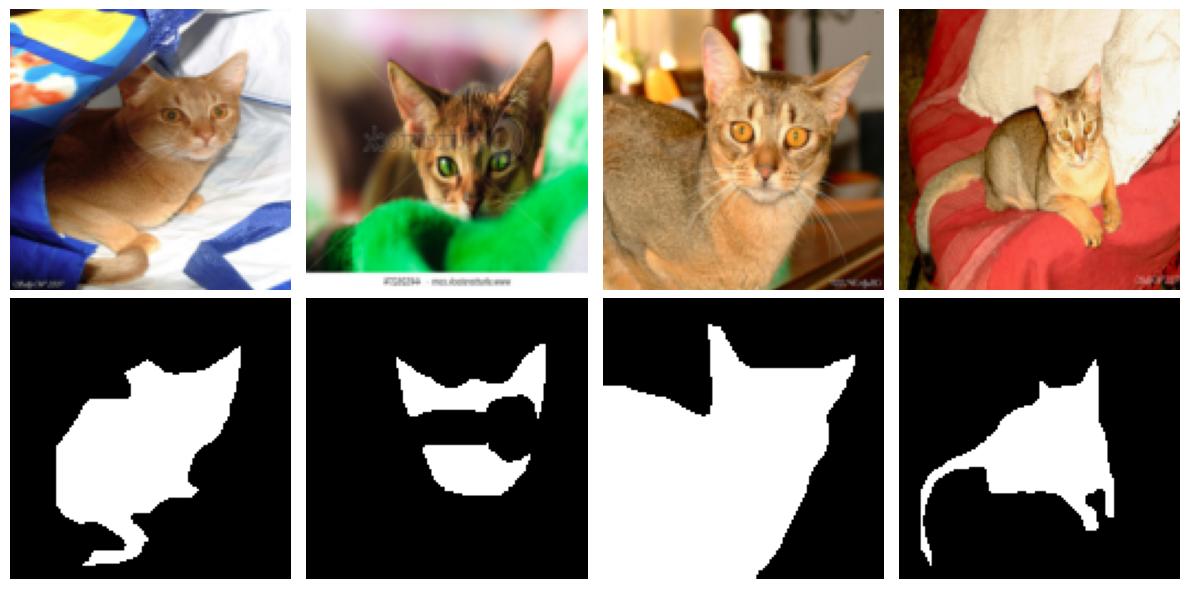

In [1]:
# 셀 1. 데이터 준비
import time, random
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
from PIL import Image

# ── 설정 ─────────────────────────────────────────────
OPTION       = "pet"     # "pet" = Oxford-IIIT Pet, "voc" = PASCAL VOC 2012
TASK         = "binary"  # "binary" = 대상 1 / 나머지 0, "multi" = 클래스 여러 개
PET_POSITIVE = [1]       # pet + binary: 대상으로 볼 trimap 값 (1 반려동물, 2 배경, 3 경계)
VOC_TARGET   = [15]      # voc + binary: 대상으로 볼 VOC 클래스 번호 (15 person, 8 cat, 12 dog ...)
IMG_SIZE     = 128       # 2**풀링횟수 로 나누어떨어지게
N_TRAIN      = None      # None이면 전부
N_TEST       = 500       # 시험에 쓸 장 수
BATCH_SIZE   = 16
AUGMENT      = True      # 좌우 뒤집기를 사진과 마스크에 같이
SEED         = 0
IGNORE       = 255       # 손실과 IoU에서 빼는 픽셀 (VOC 경계 255)
# ────────────────────────────────────────────────────

torch.manual_seed(SEED); random.seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":                      # 시험 규칙: GPU가 없으면 300장, 128, 2에폭
    N_TRAIN, IMG_SIZE = 300, 128
print("device:", device)

if OPTION == "pet":
    raw_train = datasets.OxfordIIITPet("data", split="trainval", target_types="segmentation", download=True)
    raw_test  = datasets.OxfordIIITPet("data", split="test",     target_types="segmentation", download=True)
    NUM_CLASSES = 1 if TASK == "binary" else 3
    CLASS_NAMES = ["pet"] if TASK == "binary" else ["pet", "background", "border"]
else:
    raw_train = datasets.VOCSegmentation("data", year="2012", image_set="train", download=True)
    raw_test  = datasets.VOCSegmentation("data", year="2012", image_set="val",   download=True)
    NUM_CLASSES = 1 if TASK == "binary" else 21
    CLASS_NAMES = (["target"] if TASK == "binary" else
                   ["background", "aeroplane", "bicycle", "bird", "boat", "bottle", "bus", "car", "cat", "chair",
                    "cow", "diningtable", "dog", "horse", "motorbike", "person", "pottedplant", "sheep",
                    "sofa", "train", "tvmonitor"])
print(f"원본: 학습 {len(raw_train)}장, 시험 {len(raw_test)}장")

def make_label(raw_mask):
    """원본 마스크(PIL) → 정답 배열 (H,W) int64. binary는 0/1, multi는 0..K-1, 무시할 픽셀은 IGNORE."""
    m = np.array(raw_mask).astype(np.int64)
    if OPTION == "pet":
        if TASK == "binary":
            return np.isin(m, PET_POSITIVE).astype(np.int64)
        return m - 1                               # trimap 1,2,3 → 0 반려동물, 1 배경, 2 경계
    out = np.where(np.isin(m, VOC_TARGET), 1, 0) if TASK == "binary" else m.copy()
    out[m == 255] = IGNORE                         # VOC 경계(void)는 손실·IoU에서 뺀다
    return out

class SegDataset(Dataset):
    def __init__(self, raw, n=None, size=IMG_SIZE, augment=False):
        n = len(raw) if n is None else min(n, len(raw))
        self.augment = augment
        self.images, self.masks = [], []
        t0 = time.time()
        for i in range(n):
            img, mask = raw[i]
            img  = img.convert("RGB").resize((size, size), Image.BILINEAR)   # 사진은 부드럽게
            mask = mask.resize((size, size), Image.NEAREST)                  # 마스크는 값이 섞이지 않게
            self.images.append(np.array(img, dtype=np.uint8))
            self.masks.append(make_label(mask).astype(np.uint8))
        print(f"  {n}장 전처리 ({time.time() - t0:.0f}초)")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        x = torch.tensor(self.images[idx], dtype=torch.float32).permute(2, 0, 1) / 255.0   # (3,H,W) 0~1
        y = torch.tensor(self.masks[idx], dtype=torch.long)                                # (H,W)
        if self.augment and random.random() < 0.5:                                         # 같은 뒤집기를 둘 다에
            x, y = x.flip(-1), y.flip(-1)
        return x, y

train_set = SegDataset(raw_train, N_TRAIN, augment=AUGMENT)
test_set  = SegDataset(raw_test, N_TEST, augment=False)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_set, batch_size=BATCH_SIZE)

# 확인: 장 수, 모양, 값, 클래스 비율
x, y = train_set[0]
all_masks = np.stack(train_set.masks)
valid = all_masks != IGNORE
print(f"len(train_set) {len(train_set)}, len(test_set) {len(test_set)}, 에폭당 배치 {len(train_loader)}")
print("입력", tuple(x.shape), x.dtype, "| 정답", tuple(y.shape), y.dtype, "| 정답 값", sorted(np.unique(all_masks).tolist()))
print(f"무시 픽셀(IGNORE) 비율: {(~valid).mean():.1%}")
if TASK == "binary":
    pos = (all_masks == 1).sum() / valid.sum()
    empty = np.mean([(m == 1).sum() == 0 for m in train_set.masks])
    POS_RATIO = float(pos)
    print(f"대상 픽셀 비율: {pos:.1%} | 대상이 없는 사진 비율: {empty:.1%}")
else:
    counts = np.bincount(all_masks[valid].ravel(), minlength=NUM_CLASSES)
    CLASS_RATIO = counts / counts.sum()
    for k, r in enumerate(CLASS_RATIO):
        print(f"  {k:2d} {CLASS_NAMES[k]:<12s} {r:.2%}")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for j in range(4):
    xi, yi = train_set[j]
    axes[0, j].imshow(xi.permute(1, 2, 0)); axes[0, j].axis("off")
    show = yi.float().clone(); show[yi == IGNORE] = float("nan")
    axes[1, j].imshow(show, cmap="viridis" if TASK == "multi" else "gray"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

In [2]:
# 셀 2. 모델 구성
import torch.nn as nn
import torch.nn.functional as F

N_POOL   = 3       # 풀링 횟수 (IMG_SIZE가 2**N_POOL로 나누어떨어져야 함)
BASE_CH  = 16      # 첫 단계 채널. 단계마다 2배
USE_SKIP = True
USE_BN   = True
OUT_CH   = 1 if TASK == "binary" else NUM_CLASSES   # binary: 1채널 sigmoid, multi: K채널 로짓

def double_conv(in_ch, out_ch):
    layers = []
    for i, o in [(in_ch, out_ch), (out_ch, out_ch)]:
        layers.append(nn.Conv2d(i, o, 3, padding=1))
        if USE_BN:
            layers.append(nn.BatchNorm2d(o))
        layers.append(nn.ReLU(inplace=True))
    return nn.Sequential(*layers)

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        assert IMG_SIZE % (2 ** N_POOL) == 0
        chs = [BASE_CH * 2 ** k for k in range(N_POOL + 1)]
        self.encoders = nn.ModuleList([double_conv(3, chs[0])] +
                                      [double_conv(chs[k - 1], chs[k]) for k in range(1, N_POOL + 1)])
        self.pool = nn.MaxPool2d(2)
        self.decoders = nn.ModuleList([double_conv(chs[k + 1] + (chs[k] if USE_SKIP else 0), chs[k])
                                       for k in reversed(range(N_POOL))])
        self.final = nn.Conv2d(BASE_CH, OUT_CH, 1)

    def forward(self, x):
        skips = []
        for k, enc in enumerate(self.encoders):
            if k > 0:
                x = self.pool(x)
            x = enc(x)
            skips.append(x)
        x = skips.pop()
        for dec in self.decoders:
            x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
            s = skips.pop()
            x = dec(torch.cat([s, x], dim=1) if USE_SKIP else x)
        out = self.final(x)
        return torch.sigmoid(out) if TASK == "binary" else out     # multi는 로짓 그대로 (CE가 softmax)

model = UNet().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"파라미터 수: {n_params:,}  (N_POOL={N_POOL}, BASE_CH={BASE_CH}, USE_SKIP={USE_SKIP}, USE_BN={USE_BN}, OUT_CH={OUT_CH})")

# 단계별 출력 모양 (구조 그림용)과 단계별 파라미터 (파라미터 계산 표용)
def hook(name):
    return lambda m, i, o: print(f"  {name:<10s} 입력 {tuple(i[0].shape[1:])} → 출력 {tuple(o.shape[1:])}  "
                                 f"파라미터 {sum(p.numel() for p in m.parameters()):,}")
hs = [m.register_forward_hook(hook(f"enc{k + 1}" if k < N_POOL else "bottleneck")) for k, m in enumerate(model.encoders)]
hs += [m.register_forward_hook(hook(f"dec{N_POOL - k}")) for k, m in enumerate(model.decoders)]
hs += [model.final.register_forward_hook(hook("final 1x1"))]
with torch.no_grad():
    out = model(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE, device=device))
for h in hs:
    h.remove()
print("입력", (2, 3, IMG_SIZE, IMG_SIZE), "→ 출력", tuple(out.shape))

파라미터 수: 488,705  (N_POOL=3, BASE_CH=16, USE_SKIP=True, USE_BN=True, OUT_CH=1)


  enc1       입력 (3, 128, 128) → 출력 (16, 128, 128)  파라미터 2,832
  enc2       입력 (16, 64, 64) → 출력 (32, 64, 64)  파라미터 14,016
  enc3       입력 (32, 32, 32) → 출력 (64, 32, 32)  파라미터 55,680
  bottleneck 입력 (64, 16, 16) → 출력 (128, 16, 16)  파라미터 221,952


  dec3       입력 (192, 32, 32) → 출력 (64, 32, 32)  파라미터 147,840
  dec2       입력 (96, 64, 64) → 출력 (32, 64, 64)  파라미터 37,056
  dec1       입력 (48, 128, 128) → 출력 (16, 128, 128)  파라미터 9,312
  final 1x1  입력 (16, 128, 128) → 출력 (1, 128, 128)  파라미터 17
입력 (2, 3, 128, 128) → 출력 (2, 1, 128, 128)


In [3]:
# 셀 3. 손실 함수와 옵티마이저
LR           = 1e-3
POS_WEIGHT   = None    # binary: None, 숫자, 또는 "auto"(음성/양성 픽셀 비의 제곱근). 대상이 작을 때 양성 픽셀에 가중치
CLASS_WEIGHT = None    # multi: None 또는 "auto"(1/√비율, 평균 1로 맞춤). 픽셀이 적은 클래스에 가중치

if TASK == "binary":
    pw = (np.sqrt((1 - POS_RATIO) / POS_RATIO) if POS_WEIGHT == "auto" else POS_WEIGHT)
    print(f"손실: BCELoss (픽셀별, IGNORE 제외){'' if pw is None else f', 양성 가중치 {pw:.2f}'}")
    bce = nn.BCELoss(reduction="none")
    def criterion(pred, target):               # pred (B,H,W) 확률, target (B,H,W) long 0/1/IGNORE
        valid = (target != IGNORE).float()
        t = target.clamp(max=1).float()
        w = valid if pw is None else valid * torch.where(t == 1, torch.tensor(pw, device=t.device), torch.tensor(1.0, device=t.device))
        return (bce(pred, t) * w).sum() / valid.sum().clamp(min=1)
else:
    cw = None
    if CLASS_WEIGHT == "auto":
        cw = 1 / np.sqrt(np.maximum(CLASS_RATIO, 1e-6)); cw = cw / cw.mean()
        print("클래스 가중치:", np.round(cw, 2).tolist())
        cw = torch.tensor(cw, dtype=torch.float32, device=device)
    print("손실: CrossEntropyLoss (모델 출력은 로짓, 정답은 long, IGNORE 제외)")
    criterion = nn.CrossEntropyLoss(weight=cw, ignore_index=IGNORE)

optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def evaluate(model, loader):
    """binary: 대상이 있는 사진의 사진별 IoU 평균 + 대상 없는 사진의 오탐 비율.
       multi: 시험 전체에서 클래스별 IoU를 구하고 평균(mIoU)."""
    model.eval()
    total_loss, n = 0.0, 0
    ious, fp_ratio = [], []
    inter = np.zeros(max(NUM_CLASSES, 1)); union = np.zeros(max(NUM_CLASSES, 1))
    correct = valid_px = 0
    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            out = model(images)
            if TASK == "binary":
                pred_prob = out.squeeze(1)
                total_loss += criterion(pred_prob, masks).item() * len(images)
                pred = pred_prob > 0.5
                for p, t in zip(pred, masks):
                    v = t != IGNORE; t1 = (t == 1) & v; p1 = p & v
                    correct += (p1 == t1)[v].sum().item(); valid_px += v.sum().item()
                    if t1.sum() == 0:
                        fp_ratio.append(p1.float().sum().item() / v.sum().item())   # 대상 없는 사진: 잘못 칠한 비율
                    else:
                        ious.append(((p1 & t1).sum() / (p1 | t1).sum()).item())
            else:
                total_loss += criterion(out, masks).item() * len(images)
                pred = out.argmax(1)
                v = masks != IGNORE
                correct += (pred == masks)[v].sum().item(); valid_px += v.sum().item()
                for k in range(NUM_CLASSES):
                    pk, tk = (pred == k) & v, (masks == k) & v
                    inter[k] += (pk & tk).sum().item(); union[k] += (pk | tk).sum().item()
            n += len(images)
    res = {"loss": total_loss / n, "pixel_acc": correct / max(valid_px, 1)}
    if TASK == "binary":
        res["iou"] = float(np.mean(ious)) if ious else float("nan")
        res["n_empty"] = len(fp_ratio)
        res["fp_on_empty"] = float(np.mean(fp_ratio)) if fp_ratio else float("nan")
    else:
        cls_iou = np.where(union > 0, inter / np.maximum(union, 1), np.nan)
        res["iou"] = float(np.nanmean(cls_iou)); res["class_iou"] = cls_iou
    return res

r0 = evaluate(model, test_loader)
print(f"학습 전 시험 손실 {r0['loss']:.4f}, IoU {r0['iou']:.4f}  (binary라면 모든 픽셀 0.5 예측 시 BCE = ln2 ≈ 0.693)")

손실: BCELoss (픽셀별, IGNORE 제외)


학습 전 시험 손실 0.6862, IoU 0.0000  (binary라면 모든 픽셀 0.5 예측 시 BCE = ln2 ≈ 0.693)


Epoch 1/3  train loss 0.4433 | test loss 0.3368 | test IoU 0.5760  (9.2s, 누적 10s)


Epoch 2/3  train loss 0.3093 | test loss 0.3608 | test IoU 0.5994  (9.2s, 누적 21s)


Epoch 3/3  train loss 0.2705 | test loss 0.2735 | test IoU 0.6346  (9.1s, 누적 31s)
총 학습 시간 31초, 에폭당 평균 9.2초


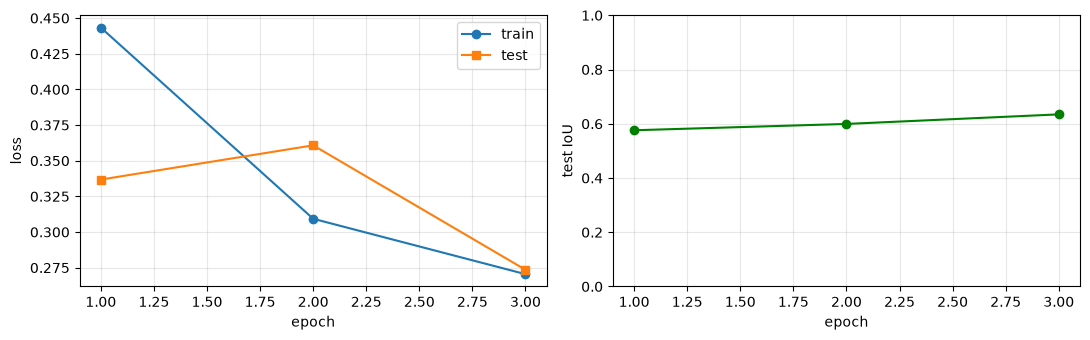

In [4]:
# 셀 4. 학습 루프
EPOCHS         = 3
TIME_LIMIT_MIN = 20    # 학습 시간 상한 (분). 다음 에폭이 넘길 것 같으면 멈춤
if device.type == "cpu":
    EPOCHS = 2         # 시험 규칙: GPU가 없으면 2에폭

history = {"train_loss": [], "test_loss": [], "test_iou": [], "epoch_sec": []}
t_start = time.time()
for epoch in range(EPOCHS):
    model.train()
    t0 = time.time(); total, n = 0.0, 0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        out = model(images)
        loss = criterion(out.squeeze(1), masks) if TASK == "binary" else criterion(out, masks)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(images); n += len(images)
    if device.type == "cuda":
        torch.cuda.synchronize()
    sec = time.time() - t0
    r = evaluate(model, test_loader)
    for k, v in [("train_loss", total / n), ("test_loss", r["loss"]), ("test_iou", r["iou"]), ("epoch_sec", sec)]:
        history[k].append(v)
    extra = f" | 대상 없는 사진 오탐 {r['fp_on_empty']:.2%}" if TASK == "binary" and r["n_empty"] else ""
    print(f"Epoch {epoch + 1}/{EPOCHS}  train loss {total / n:.4f} | test loss {r['loss']:.4f} | "
          f"test IoU {r['iou']:.4f}{extra}  ({sec:.1f}s, 누적 {time.time() - t_start:.0f}s)")
    elapsed = time.time() - t_start
    if elapsed + sec > TIME_LIMIT_MIN * 60 and epoch + 1 < EPOCHS:
        print(f"다음 에폭이 {TIME_LIMIT_MIN}분을 넘길 것 같아 멈춤"); break

print(f"총 학습 시간 {time.time() - t_start:.0f}초, 에폭당 평균 {np.mean(history['epoch_sec']):.1f}초")
e = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(e, history["train_loss"], "o-", label="train"); axes[0].plot(e, history["test_loss"], "s-", label="test")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(e, history["test_iou"], "o-", color="green"); axes[1].set_ylim(0, 1)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("test IoU"); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

시험 500장 | 시험 IoU 0.6346 | 픽셀 정확도 0.8835
  (IoU는 대상이 있는 사진의 사진별 평균, 임계값 0.5) | 대상 없는 사진 0장의 평균 오탐 비율 nan%
파라미터 수 488,705


장당 추론 시간 5.09 ms (cuda, 128x128)


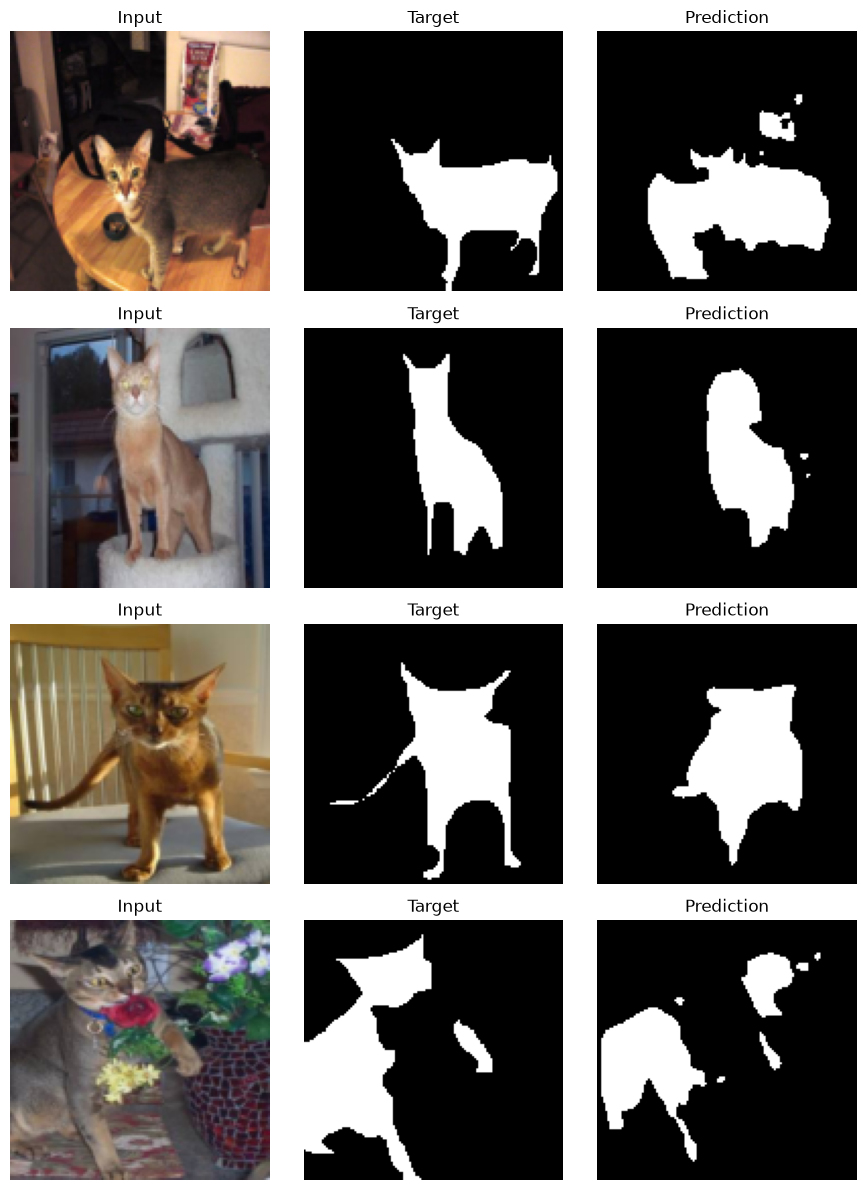

In [5]:
# 셀 5. 결과 확인
r = evaluate(model, test_loader)
print(f"시험 {len(test_set)}장 | 시험 IoU {r['iou']:.4f} | 픽셀 정확도 {r['pixel_acc']:.4f}")
if TASK == "binary":
    print(f"  (IoU는 대상이 있는 사진의 사진별 평균, 임계값 0.5) | 대상 없는 사진 {r['n_empty']}장의 평균 오탐 비율 {r['fp_on_empty']:.2%}")
else:
    for k, v in enumerate(r["class_iou"]):
        print(f"  {k:2d} {CLASS_NAMES[k]:<12s} IoU {v:.3f}")
print(f"파라미터 수 {n_params:,}")

# 장당 추론 시간 (배치 1, 워밍업 뒤 50번 평균)
model.eval()
x1 = test_set[0][0].unsqueeze(0).to(device)
with torch.no_grad():
    for _ in range(10):
        model(x1)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(50):
        model(x1)
    if device.type == "cuda":
        torch.cuda.synchronize()
print(f"장당 추론 시간 {(time.time() - t0) / 50 * 1000:.2f} ms ({device}, {IMG_SIZE}x{IMG_SIZE})")

# Input / Target / Prediction 4장
fig, axes = plt.subplots(4, 3, figsize=(9, 12))
for k in range(4):
    xi, yi = test_set[k]
    with torch.no_grad():
        out = model(xi.unsqueeze(0).to(device)).cpu()
    pred = (out[0, 0] > 0.5).float() if TASK == "binary" else out[0].argmax(0).float()
    tgt = yi.float().clone(); tgt[yi == IGNORE] = float("nan")
    cmap = "gray" if TASK == "binary" else "viridis"
    vmax = 1 if TASK == "binary" else NUM_CLASSES - 1
    axes[k, 0].imshow(xi.permute(1, 2, 0)); axes[k, 0].set_title("Input")
    axes[k, 1].imshow(tgt, cmap=cmap, vmin=0, vmax=vmax); axes[k, 1].set_title("Target")
    axes[k, 2].imshow(pred, cmap=cmap, vmin=0, vmax=vmax); axes[k, 2].set_title("Prediction")
    for ax in axes[k]:
        ax.axis("off")
plt.tight_layout(); plt.show()